# Class 3: Data visualization

_"Data visualization", "chart", "graph", and  will be used interchangeably._

## **Today's goal**: Visualizing requests per community district

This should help us better understand trends across the city.

## Start by importing necessary packages

In [1]:
import pandas as pd
import plotly.express as px

## Populations

Load the data:

In [2]:
population = pd.read_csv("https://data.cityofnewyork.us/api/views/xi7c-iiu2/rows.csv")
population.head()

,Borough,CD Number,CD Name,1970 Population,1980 Population,1990 Population,2000 Population,2010 Population
0,Bronx,1,"Melrose, Mott Haven, Port Morris",138557,78441,77214,82159,91497
1,Bronx,2,"Hunts Point, Longwood",99493,34399,39443,46824,52246
2,Bronx,3,"Morrisania, Crotona Park East",150636,53635,57162,68574,79762
3,Bronx,4,"Highbridge, Concourse Village",144207,114312,119962,139563,146441
4,Bronx,5,"University Hts., Fordham, Mt. Hope",121807,107995,118435,128313,128200


Adapting [the basic histogram example](https://plotly.com/python/histograms/):

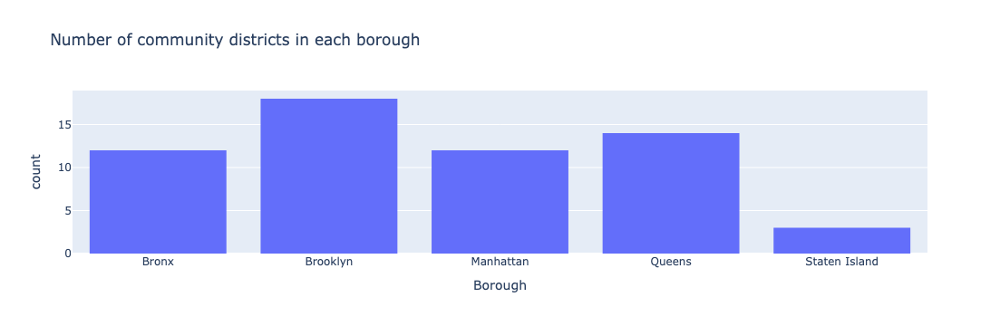

In [3]:
fig = px.histogram(
    population,
    x="Borough",
    title="Number of community districts in each borough",
)
fig.show()

Histogram values are equivalent to doing a `.groupby().size()`.

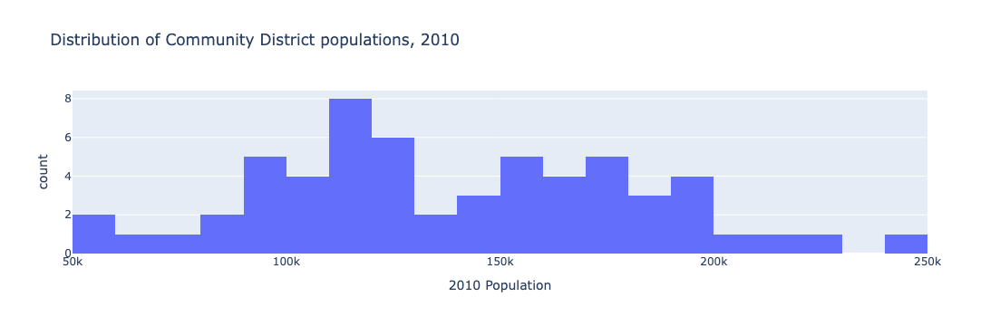

In [4]:
fig = px.histogram(
    population,
    x="2010 Population",
    title="Distribution of Community District populations, 2010",
    nbins=20,
)
fig.show()

## Data from where we left off last class

[Derived dataset containing count of complaints per community district.](https://python-public-policy.afeld.me/en/columbia/lecture_2.html#join-the-population-data-onto-the-counts-data-after-creating-shared-borocd-unique-id)

In [5]:
districts = pd.read_csv(
    "https://storage.googleapis.com/python-public-policy2/data/community_district_311.csv.zip"
)
districts.head()

,Community Board,num_311_requests,boro_cd,Borough,CD Number,CD Name,1970 Population,1980 Population,1990 Population,2000 Population,2010 Population
0,12 MANHATTAN,14110,112,Manhattan,12,"Washington Heights, Inwood",180561,179941,198192,208414,190020
1,05 QUEENS,12487,405,Queens,5,"Ridgewood, Glendale, Maspeth",161022,150142,149126,165911,169190
2,12 QUEENS,12228,412,Queens,12,"Jamaica, St. Albans, Hollis",206639,189383,201293,223602,225919
3,01 BROOKLYN,11863,301,Brooklyn,1,"Williamsburg, Greenpoint",179390,142942,155972,160338,173083
4,03 BROOKLYN,11615,303,Brooklyn,3,Bedford Stuyvesant,203380,133379,138696,143867,152985


Looking at raw volume is probably less useful than density.

## Calculate 311 requests per capita

Divide request count by 2010 population to get requests per capita

In [6]:
districts["requests_per_capita"] = districts["num_311_requests"] / districts["2010 Population"]

districts.head()

,Community Board,num_311_requests,boro_cd,Borough,CD Number,CD Name,1970 Population,1980 Population,1990 Population,2000 Population,2010 Population,requests_per_capita
0,12 MANHATTAN,14110,112,Manhattan,12,"Washington Heights, Inwood",180561,179941,198192,208414,190020,0.074255
1,05 QUEENS,12487,405,Queens,5,"Ridgewood, Glendale, Maspeth",161022,150142,149126,165911,169190,0.073805
2,12 QUEENS,12228,412,Queens,12,"Jamaica, St. Albans, Hollis",206639,189383,201293,223602,225919,0.054126
3,01 BROOKLYN,11863,301,Brooklyn,1,"Williamsburg, Greenpoint",179390,142942,155972,160338,173083,0.068539
4,03 BROOKLYN,11615,303,Brooklyn,3,Bedford Stuyvesant,203380,133379,138696,143867,152985,0.075922


Let's create a simplified new dataframe that only include the columns we care about and in a better order.

In [7]:
columns = [
    "boro_cd",
    "Borough",
    "CD Name",
    "2010 Population",
    "num_311_requests",
    "requests_per_capita",
]
cd_data = districts[columns]

cd_data

,boro_cd,Borough,CD Name,2010 Population,num_311_requests,requests_per_capita
0,112,Manhattan,"Washington Heights, Inwood",190020,14110,0.074255
1,405,Queens,"Ridgewood, Glendale, Maspeth",169190,12487,0.073805
2,412,Queens,"Jamaica, St. Albans, Hollis",225919,12228,0.054126
3,301,Brooklyn,"Williamsburg, Greenpoint",173083,11863,0.068539
4,303,Brooklyn,Bedford Stuyvesant,152985,11615,0.075922
5,501,Staten Island,"Stapleton, Port Richmond",175756,11438,0.065079
6,407,Queens,"Flushing, Bay Terrace",247354,11210,0.045320
7,305,Brooklyn,"East New York, Starrett City",182896,10862,0.059389
8,204,Bronx,"Highbridge, Concourse Village",146441,10628,0.072575
9,401,Queens,"Astoria, Long Island City",191105,10410,0.054473


Let's check out which Community Districts have the highest complaints per capita

In [8]:
cd_data.sort_values("requests_per_capita", ascending=False).head(10)

,boro_cd,Borough,CD Name,2010 Population,num_311_requests,requests_per_capita
38,105,Manhattan,Midtown Business District,51673,6599,0.127707
30,308,Brooklyn,Crown Heights North,96317,7797,0.080951
31,302,Brooklyn,"Brooklyn Heights, Fort Greene",99617,7747,0.077768
32,309,Brooklyn,"Crown Heights South, Wingate",98429,7571,0.076918
21,304,Brooklyn,Bushwick,112634,8639,0.076700
4,303,Brooklyn,Bedford Stuyvesant,152985,11615,0.075922
0,112,Manhattan,"Washington Heights, Inwood",190020,14110,0.074255
22,110,Manhattan,Central Harlem,115723,8592,0.074246
1,405,Queens,"Ridgewood, Glendale, Maspeth",169190,12487,0.073805
8,204,Bronx,"Highbridge, Concourse Village",146441,10628,0.072575


While Inwood (112) had the highest number of complaints, it ranks further down on the list for requests per capita. Midtown may also be an outlier, based on it's low residential population.

In [9]:
# cd_data.to_csv("data/311_community_districts.csv", index=False)

## [In-class exercise](https://python-public-policy.afeld.me/en/columbia/lecture_3_exercise.html)

How does the per-capita distribution compare to that of the raw counts?

In [10]:
fig = px.histogram(districts, x="requests_per_capita", height=200)
fig.show()

In [11]:
fig = px.histogram(districts, x="num_311_requests", height=200)
fig.show()

Let's [improve the formatting](https://plotly.com/python/figure-labels/) (based on [the `.histogram()` documentation](https://plotly.com/python-api-reference/generated/plotly.express.histogram.html)):

In [12]:
fig = px.histogram(
    districts,
    x="requests_per_capita",
    title="Volume of 311 requests, 2018-2019",
    labels={"requests_per_capita": "311 requests per capita"},
)

# y-axis needs to be done separately, since it's derived
fig.update_layout(yaxis_title_text="Number of community districts")
fig.show()

## Scatterplot

In [13]:
fig = px.scatter(
    districts,
    x="2010 Population",
    y="num_311_requests",
    title="Number of 311 requests per Community District by population",
)

fig.show()

[Add a trendline](https://plotly.com/python/linear-fits/):

In [14]:
fig = px.scatter(
    districts,
    x="2010 Population",
    y="num_311_requests",
    title="Number of 311 requests per Community District by population",
    trendline="ols",
)

fig.show()

Let's take a look at the statistical summary, via the [`statsmodels`](https://www.statsmodels.org/) package, following [Plotly's example](https://plotly.com/python/linear-fits/#fitting-multiple-lines-and-retrieving-the-model-parameters):

In [15]:
trend_results = px.get_trendline_results(fig).iloc[0, 0]
trend_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.469
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     50.39
Date:                Fri, 20 Sep 2024   Prob (F-statistic):           2.18e-09
Time:                        23:22:40   Log-Likelihood:                -523.81
No. Observations:                  59   AIC:                             1052.
Df Residuals:                      57   BIC:                             1056.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2692.4746    773.994      3.479      0.001    1142.578    4242.371
x1             0.0379      0.005      7.099      0.000       0.027       0.049
==============================================================================
Omnibus:                        0.047   Durbin-Watson:                   1.999
Prob(Omnibus):                  0.977   Jarque-Bera (JB):                0.080
Skew:                          -0.052   Prob(JB):                        0.961
Kurtosis:                       2.853   Cond. No.                     4.88e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.88e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

["In general, the higher the R-squared, the better the model fits your data."](https://blog.minitab.com/blog/adventures-in-statistics-2/regression-analysis-how-do-i-interpret-r-squared-and-assess-the-goodness-of-fit)

## Map complaint counts by CD

We'll follow [this example](https://plotly.com/python/choropleth-maps/#indexing-by-geojson-properties), using [community district GIS data](https://data.cityofnewyork.us/City-Government/Community-Districts/yfnk-k7r4).

_Jump ahead to the map_

First, let's take a look at the GeoJSON data. We're looking for what we can [match our `boro_cd` column up to](https://plotly.com/python/mapbox-county-choropleth/#indexing-by-geojson-properties). One way to inspect it:

1. Open [Chrome](https://www.google.com/chrome/downloads/)
1. Install [JSON Viewer](https://chrome.google.com/webstore/detail/json-viewer/gbmdgpbipfallnflgajpaliibnhdgobh)
1. Open https://data.cityofnewyork.us/resource/jp9i-3b7y.geojson

Load the GeoJSON data using [the requests package](https://docs.python-requests.org/) (nothing to do with 311 requests):

In [16]:
import requests

response = requests.get("https://data.cityofnewyork.us/resource/jp9i-3b7y.geojson")
shapes = response.json()
print("loaded")

# intentionally not outputting the data here since it's large

loaded


_This is equivalent to the use of [`urlopen()`](https://docs.python.org/3/library/urllib.request.html#urllib.request.urlopen) and [`json.load()`](https://docs.python.org/3/library/json.html) in [the Plotly examples](https://plotly.com/python/mapbox-county-choropleth/)._

The structure looks something like:

```
{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "geometry": {
        "type": "MultiPolygon",
        "coordinates": [
          [
            [
              [-73.8718461029101, 40.843760777855834],
              …
            ]
          ]
        ]
      },
      "properties": {
        "boro_cd": "206",
        "shape_leng": "35875.7117328",
        "shape_area": "42664311.5086"
      }
    },
    …
  ]
}
```

Peek at the `properties` of one of the `features` a.k.a. shapes a.k.a. Community Districts:

In [17]:
shapes["features"][0]["properties"]

{'boro_cd': '308',
 'shape_leng': '38232.8866492',
 'shape_area': '45603787.1251'}

Notes:

- `boro_cd` is the property we're looking for. We'll [specify this as the `featureidkey`](https://plotly.com/python/mapbox-county-choropleth/#indexing-by-geojson-properties).
- `response.json()` turns JSON data into nested Python objects: `shapes` is a dictionary, `features` is a list beneath it, etc.

In [18]:
def plot_nyc(df):
    fig = px.choropleth_mapbox(
        df,
        locations="boro_cd",  # column name to match on
        color="requests_per_capita",  # column name for values
        geojson=shapes,
        featureidkey="properties.boro_cd",  # GeoJSON property to match on
        center={"lat": 40.71, "lon": -73.98},
        zoom=9,
        mapbox_style="carto-positron",
        height=600,
        title="Requests per capita across Community Districts",
    )

    fig.show()

Wrapping this Plotly code in a function to:

- Save space on subsequent slides
- Make the code reusable for plotting different DataFrames

In [19]:
plot_nyc(districts)

Midtown, as an outlier, is skewing our results. Let's exclude it.

In [20]:
no_midtown = districts[districts["boro_cd"] != 105]
plot_nyc(no_midtown)

**Fun fact** (for a certain kind of person): [What the Mapbox zoom level means](https://docs.mapbox.com/help/glossary/zoom-level/)

## Chart hygiene

- Always include a title
- Make sure you label dependent and independent variables (X and Y axes)
- Consider whether you are working with continuous vs. discrete values
- If you're trying to show more than three variables at once (e.g. X axis, Y axis, and color), try simplifying

## What visualization should I use?

Rudimentary guidelines:

What do you want to do? | Chart type
:-- | :-:
Show changes over time | Line chart
Compare values for categorical data | Bar chart
Compare two numeric variables | Scatter plot
Count things / show distribution across a range | Histogram
Show geographic trends | [Map (choropleth, hexbin, bubble, etc.)](https://plotly.com/python/maps/)

The [Data Design Standards](https://xdgov.github.io/data-design-standards/visualizations/) goes into more detail.

## Pivoting

FYI: Pandas supports [reshaping](https://pandas.pydata.org/pandas-docs/stable/user_guide/reshaping.html) DataFrames through [pivoting](https://pandas.pydata.org/pandas-docs/stable/user_guide/reshaping.html#reshaping-by-pivoting-dataframe-objects), [like spreadsheets do](https://support.google.com/docs/answer/1272900).

<video controls width="700" src="https://github.com/afeld/python-public-policy/raw/main/extras/img/pivot.mp4"></video>

## [Homework 3](https://python-public-policy.afeld.me/en/columbia/hw_3.html)

## Final Project

In real/ideal world, start with specific question and find data to answer it:

![project flow](extras/img/projectflow.png)

_Source: [Big Data and Social Science](https://textbook.coleridgeinitiative.org/chap-intro.html#the-structure-of-the-book)_

Data needed often doesn't exist or is hard (or impossible) to find/access

![project flow](extras/img/projectflow_amended.png)

[Final Project](https://python-public-policy.afeld.me/en/columbia/final_project.html)